<a href="https://colab.research.google.com/github/zouhiraghenaim/Supervised-Learning-Algorithms/blob/main/TP6_Random_Forest/TP6_02__Random_Forest_on_Bank_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Random Forest on Bank Dataset**

**Objective** :
Predict whether a bank client will subscribe to a term deposit (**deposit = yes/no**) using a Random Forest classifier, following the theoretical framework : **Bootstrap Aggregating**, **Out-of-Bag validation**,**Feature Randomness (m ≈ √P)**, and **Majority Voting**.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## **DataFrame Initialization & Data Preparation**

The bank dataset has 17 columns. We must additionally:
*   Clean 'unknown' values,
*   Fix the placeholder pdays = -1,
*   Encode categoricals,
*   Remove duration (leaks target information — it is unknown before the call ends).




In [2]:

#  1.1 Load the dataset into a DataFrame
uploaded = files.upload()   # upload bank.csv when prompted
df = pd.read_csv("bank.csv", sep=";")

print(f"Shape: {df.shape}")
print(df.head())

#  1.2 Inspect 'unknown' values (implicit missing)
unknown_pct = (df == "unknown").sum() / len(df) * 100
print("\nColumns containing 'unknown':")
print(unknown_pct[unknown_pct > 0].round(2))

# --- 1.3 Replace 'unknown' with NaN for accurate handling
df_clean = df.replace("unknown", np.nan)

# --- 1.4 Handle the placeholder pdays = -1
#         (-1 means "client was never contacted before")
df_clean["previously_contacted"] = (df_clean["pdays"] != -1).astype(int)
df_clean.loc[df_clean["pdays"] == -1, "pdays"] = np.nan
df_clean["pdays"] = df_clean["pdays"].fillna(0)

# --- 1.5 Handle remaining missing values
# poutcome: mostly NaN because clients were not contacted before
df_clean["poutcome"] = df_clean["poutcome"].fillna("not_contacted")

# contact: 21% missing → keep a "missing" indicator + a category
df_clean["contact_missing"] = df_clean["contact"].isna().astype(int)
df_clean["contact"] = df_clean["contact"].fillna("unknown")

# job / education: low missing → impute with mode
for col in ["job", "education"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

assert df_clean.isnull().sum().sum() == 0, "Still has NaN!"
print("\n  All missing values handled.")

# --- 1.6 Encode the target variable
df_clean["deposit"] = df_clean["deposit"].map({"yes": 1, "no": 0})

# --- 1.7 One-Hot Encode categorical features
categorical_cols = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month", "poutcome",
]
df_encoded = pd.get_dummies(
    df_clean, columns=categorical_cols, drop_first=True, dtype=int
)

# --- 1.8 Separate features (X) from target (y)
#  Drop 'duration' → data leakage (unknown before the call ends)
X = df_encoded.drop(columns=["deposit", "duration"])
y = df_encoded["deposit"]

print(f"\nFeature matrix X: {X.shape}")
print(f"Target vector y : {y.shape}")
print("'duration' removed ")

# --- 1.9 Train/Test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"\nTrain: {X_train.shape} | Test: {X_test.shape}")

Saving bank.csv to bank.csv
Shape: (11162, 17)
   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   
3   55    services  married  secondary      no     2476     yes   no  unknown   
4   54      admin.  married   tertiary      no      184      no   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
3    5   may       579         1     -1         0  unknown     yes  
4    5   may       673         2     -1         0  unknown     yes  

Columns containing 'unknown':
job           0.63
ed

## **Q2 — Model Configuration**
Adaptation for Bank data: With ~40 features and 8,929 training rows, we scale accordingly:
*   n_estimators = 300 (many more trees → more stable ensemble),
*   max_features = 'sqrt' (≈ 6 ≈ √40, matching the theoretical √P rule),

*  oob_score = True, random_state = 42 (unchanged).

In [3]:

rf_model = RandomForestClassifier(
    n_estimators=300,        # 300 trees
    max_features="sqrt",     # m ≈ √P ≈ 6 features per split
    oob_score=True,          # enable Out-of-Bag internal validation
    bootstrap=True,          # Bootstrap Aggregating (bagging)
    random_state=RANDOM_STATE,
    n_jobs=-1,               # use all CPU cores
)

print("Model configured:")
print(rf_model)

Model configured:
RandomForestClassifier(n_estimators=300, n_jobs=-1, oob_score=True,
                       random_state=42)


## **Q 3: Training and Internal Validation**

In [4]:

rf_model.fit(X_train, y_train)
print(" Model trained.\n")

# Extract OOB score
oob_score = rf_model.oob_score_
oob_error_rate = 1 - oob_score

print("=" * 55)
print("INTERNAL VALIDATION — Out-of-Bag (OOB)")
print("=" * 55)
print(f"OOB Score       : {oob_score:.4f}   ({oob_score*100:.2f}%)")
print(f"OOB Error Rate  : {oob_error_rate:.4f}   ({oob_error_rate*100:.2f}%)")
print("=" * 55)

 Model trained.

INTERNAL VALIDATION — Out-of-Bag (OOB)
OOB Score       : 0.7299   (72.99%)
OOB Error Rate  : 0.2701   (27.01%)


## **Q4: Majority Vote Prediction**

In [5]:

# --- 4.1 Pick a representative test sample
sample = X_test.iloc[[0]]
true_label = y_test.iloc[0]

# --- 4.2 Forest prediction (aggregated majority vote)
forest_pred = rf_model.predict(sample)[0]
proba = rf_model.predict_proba(sample)[0]

print("=" * 55)
print("FOREST PREDICTION (MAJORITY VOTE)")
print("=" * 55)
print(f"True label             : {true_label} ({'Deposit' if true_label == 1 else 'No deposit'})")
print(f"Forest prediction      : {forest_pred} ({'Deposit' if forest_pred == 1 else 'No deposit'})")
print(f"P(No deposit)          : {proba[0]:.4f}")
print(f"P(Deposit)             : {proba[1]:.4f}")

# --- 4.3 Show the individual tree votes (the "committee")
tree_votes = np.array(
    [tree.predict(sample.values)[0] for tree in rf_model.estimators_]
)
votes_no  = (tree_votes == 0).sum()
votes_yes = (tree_votes == 1).sum()

print(f"\nIndividual tree votes (out of {len(tree_votes)} trees):")
print(f"  Trees predicting 'No deposit' : {votes_no}")
print(f"  Trees predicting 'Deposit'    : {votes_yes}")
print(f"  → Majority wins               : {1 if votes_yes > votes_no else 0}")

# --- 4.4 Hypothetical new client profile
new_client = X_test.iloc[[0]].copy()   # start from a real row (schema safety)
new_client["age"] = 40
new_client["balance"] = 1500
new_client["campaign"] = 2
if "previously_contacted" in new_client.columns:
    new_client["previously_contacted"] = 1

new_pred = rf_model.predict(new_client)[0]
new_proba = rf_model.predict_proba(new_client)[0]

print("\n" + "=" * 55)
print("HYPOTHETICAL NEW CLIENT")
print("=" * 55)
print(f"Profile: age=40, balance=1500, campaign=2, previously_contacted=1")
print(f"Predicted class : {new_pred} ({'Deposit' if new_pred == 1 else 'No deposit'})")
print(f"P(Deposit)      : {new_proba[1]:.4f}")

FOREST PREDICTION (MAJORITY VOTE)
True label             : 0 (No deposit)
Forest prediction      : 0 (No deposit)
P(No deposit)          : 0.5067
P(Deposit)             : 0.4933

Individual tree votes (out of 300 trees):
  Trees predicting 'No deposit' : 152
  Trees predicting 'Deposit'    : 148
  → Majority wins               : 0

HYPOTHETICAL NEW CLIENT
Profile: age=40, balance=1500, campaign=2, previously_contacted=1
Predicted class : 0 (No deposit)
P(Deposit)      : 0.4800


## **Q5: Tree Extraction — Audit Ensemble Architecture**

INDIVIDUAL TREE AUDIT
 Tree |  Max Depth |  # Nodes |  # Leaves
---------------------------------------------
    1 |         36 |     5053 |      2527
    2 |         37 |     5033 |      2517
    3 |         35 |     5141 |      2571
    4 |         32 |     5051 |      2526
    5 |         42 |     4909 |      2455
  296 |         31 |     5033 |      2517
  297 |         40 |     4963 |      2482
  298 |         36 |     4943 |      2472
  299 |         32 |     5055 |      2528
  300 |         35 |     4965 |      2483

SUMMARY OVER 300 TREES
Depth  → mean=35.6, min=30, max=46
Nodes  → mean=4998, min=4767, max=5199
Leaves → mean=2500, min=2384, max=2600


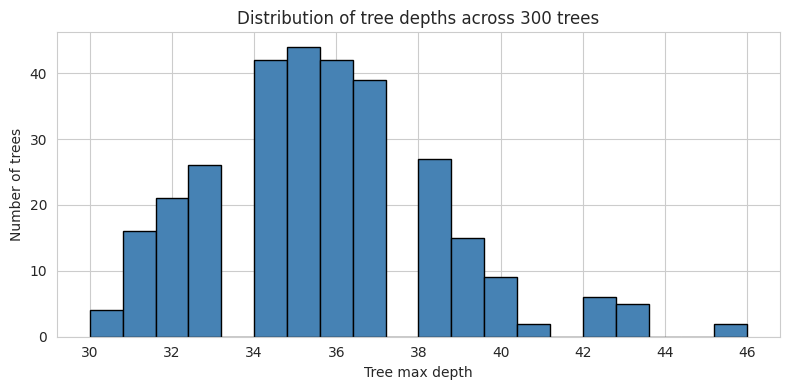

In [6]:
print("=" * 55)
print("INDIVIDUAL TREE AUDIT")
print("=" * 55)
print(f"{'Tree':>5} | {'Max Depth':>10} | {'# Nodes':>8} | {'# Leaves':>9}")
print("-" * 45)

depths, nodes, leaves = [], [], []
n_trees = len(rf_model.estimators_)

for i, tree in enumerate(rf_model.estimators_):
    depth    = tree.get_depth()
    n_nodes  = tree.tree_.node_count
    n_leaves = tree.get_n_leaves()

    depths.append(depth)
    nodes.append(n_nodes)
    leaves.append(n_leaves)

    # Show only first 5 and last 5 trees (to keep output readable)
    if i < 5 or i >= n_trees - 5:
        print(f"{i+1:>5} | {depth:>10} | {n_nodes:>8} | {n_leaves:>9}")

# --- Summary statistics across the forest
print("\n" + "=" * 55)
print(f"SUMMARY OVER {n_trees} TREES")
print("=" * 55)
print(f"Depth  → mean={np.mean(depths):.1f}, min={min(depths)}, max={max(depths)}")
print(f"Nodes  → mean={np.mean(nodes):.0f}, min={min(nodes)}, max={max(nodes)}")
print(f"Leaves → mean={np.mean(leaves):.0f}, min={min(leaves)}, max={max(leaves)}")

# --- Optional: visualize the distribution of tree depths
plt.figure(figsize=(8, 4))
plt.hist(depths, bins=20, color="steelblue", edgecolor="black")
plt.xlabel("Tree max depth")
plt.ylabel("Number of trees")
plt.title(f"Distribution of tree depths across {n_trees} trees")
plt.tight_layout()
plt.show()

**EXTENSION A: TEST-SET EVALUATION**

TEST-SET PERFORMANCE
Accuracy : 0.7241
ROC-AUC  : 0.7805

Classification Report:
              precision    recall  f1-score   support

  No Deposit      0.710     0.803     0.754      1175
     Deposit      0.744     0.636     0.686      1058

    accuracy                          0.724      2233
   macro avg      0.727     0.720     0.720      2233
weighted avg      0.726     0.724     0.722      2233



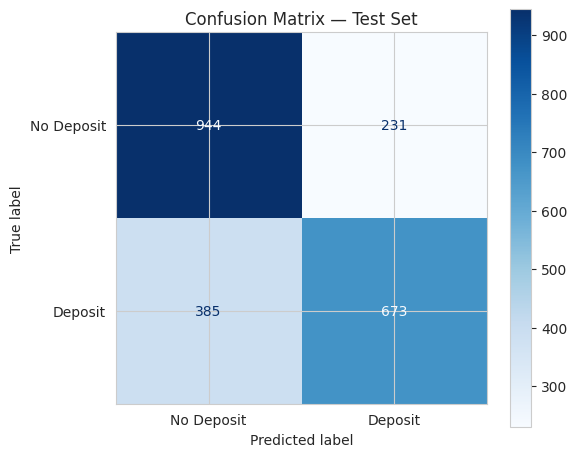

TN=944 | FP=231 | FN=385 | TP=673


In [7]:

y_pred  = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

print("=" * 55)
print("TEST-SET PERFORMANCE")
print("=" * 55)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Deposit", "Deposit"],
    digits=3,
))

# --- Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["No Deposit", "Deposit"]).plot(
    ax=ax, cmap="Blues", values_format="d"
)
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

**EXTENSION B: 5-FOLD CROSS-VALIDATION**

In [8]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_f1  = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring="f1",       n_jobs=-1)
cv_acc = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

print("=" * 55)
print("5-FOLD CROSS-VALIDATION")
print("=" * 55)
print(f"F1 scores   : {cv_f1.round(4)}")
print(f"F1 mean±std : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")
print(f"Acc scores  : {cv_acc.round(4)}")
print(f"Acc mean±std: {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")

5-FOLD CROSS-VALIDATION
F1 scores   : [0.6913 0.7018 0.7038 0.6924 0.689 ]
F1 mean±std : 0.6957 ± 0.0060
Acc scores  : [0.7284 0.7279 0.7318 0.7273 0.73  ]
Acc mean±std: 0.7291 ± 0.0016


 **EXTENSION C: FEATURE IMPORTANCE**

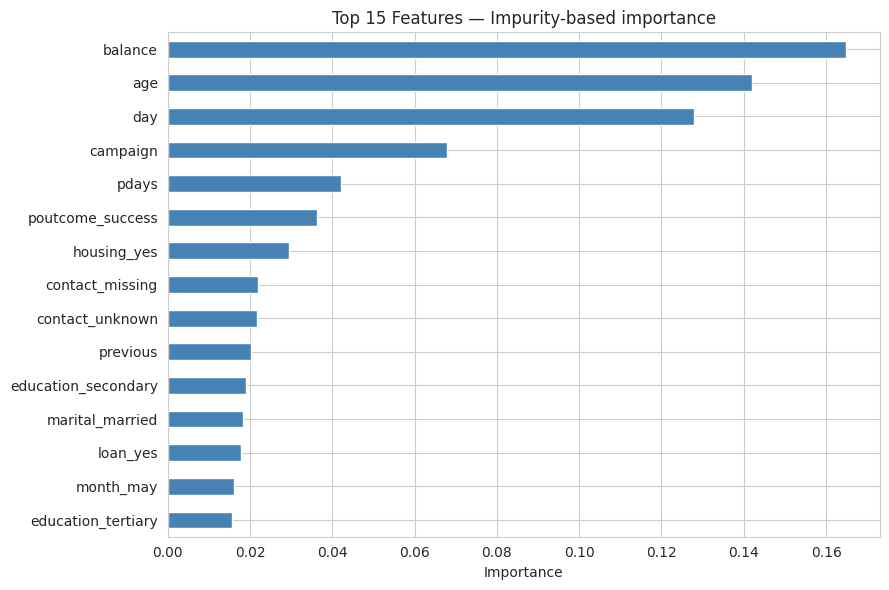

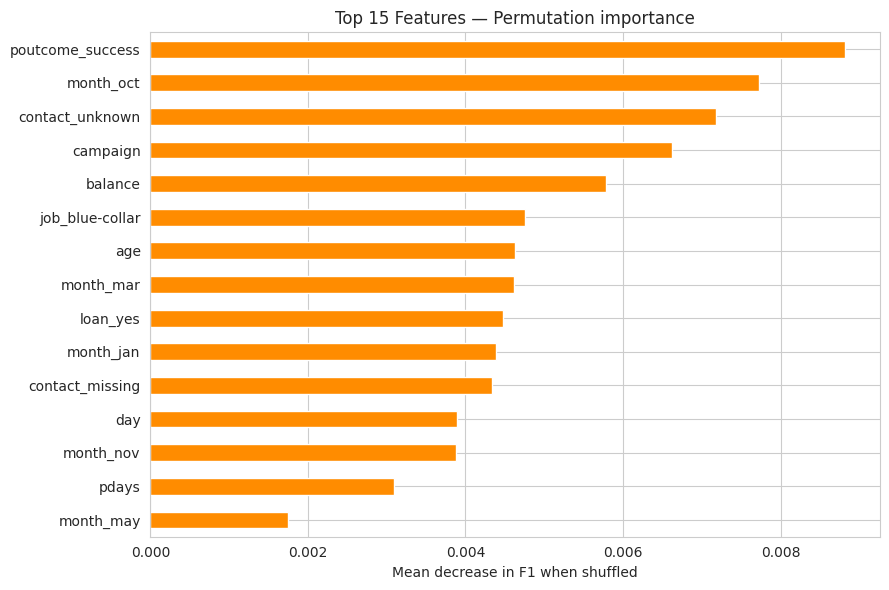

Top 10 — Permutation importance:
poutcome_success    0.0088
month_oct           0.0077
contact_unknown     0.0072
campaign            0.0066
balance             0.0058
job_blue-collar     0.0048
age                 0.0046
month_mar           0.0046
loan_yes            0.0045
month_jan           0.0044
dtype: float64


In [9]:

# --- C.1 Impurity-based (fast, but biased toward high-cardinality features)
impurity_imp = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
impurity_imp.head(15).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 15 Features — Impurity-based importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# --- C.2 Permutation importance (more reliable, reflects predictive value)
perm = permutation_importance(
    rf_model, X_test, y_test, n_repeats=10,
    random_state=RANDOM_STATE, scoring="f1", n_jobs=-1,
)
perm_imp = pd.Series(
    perm.importances_mean, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
perm_imp.head(15).sort_values().plot(kind="barh", color="darkorange")
plt.title("Top 15 Features — Permutation importance")
plt.xlabel("Mean decrease in F1 when shuffled")
plt.tight_layout()
plt.show()

print("Top 10 — Permutation importance:")
print(perm_imp.head(10).round(4))

**EXTENSION D: THRESHOLD TUNING**

In [10]:

results = []
for thr in np.arange(0.30, 0.71, 0.05):
    pred_thr = (y_proba >= thr).astype(int)
    results.append({
        "threshold": round(thr, 2),
        "precision": round(precision_score(y_test, pred_thr, zero_division=0), 3),
        "recall":    round(recall_score(y_test, pred_thr, zero_division=0), 3),
        "f1":        round(f1_score(y_test, pred_thr, zero_division=0), 3),
    })

threshold_df = pd.DataFrame(results)
print(threshold_df.to_string(index=False))

best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
print(f"\n Best threshold (by F1): {best_row['threshold']}")
print(f"   Precision={best_row['precision']}, Recall={best_row['recall']}, F1={best_row['f1']}")

 threshold  precision  recall    f1
      0.30      0.597   0.854 0.703
      0.35      0.633   0.801 0.707
      0.40      0.673   0.735 0.703
      0.45      0.706   0.684 0.695
      0.50      0.744   0.636 0.686
      0.55      0.768   0.593 0.669
      0.60      0.801   0.543 0.647
      0.65      0.819   0.479 0.605
      0.70      0.831   0.414 0.553

 Best threshold (by F1): 0.35
   Precision=0.633, Recall=0.801, F1=0.707


**VISUALIZE ONE TREE (limited depth for readability)**

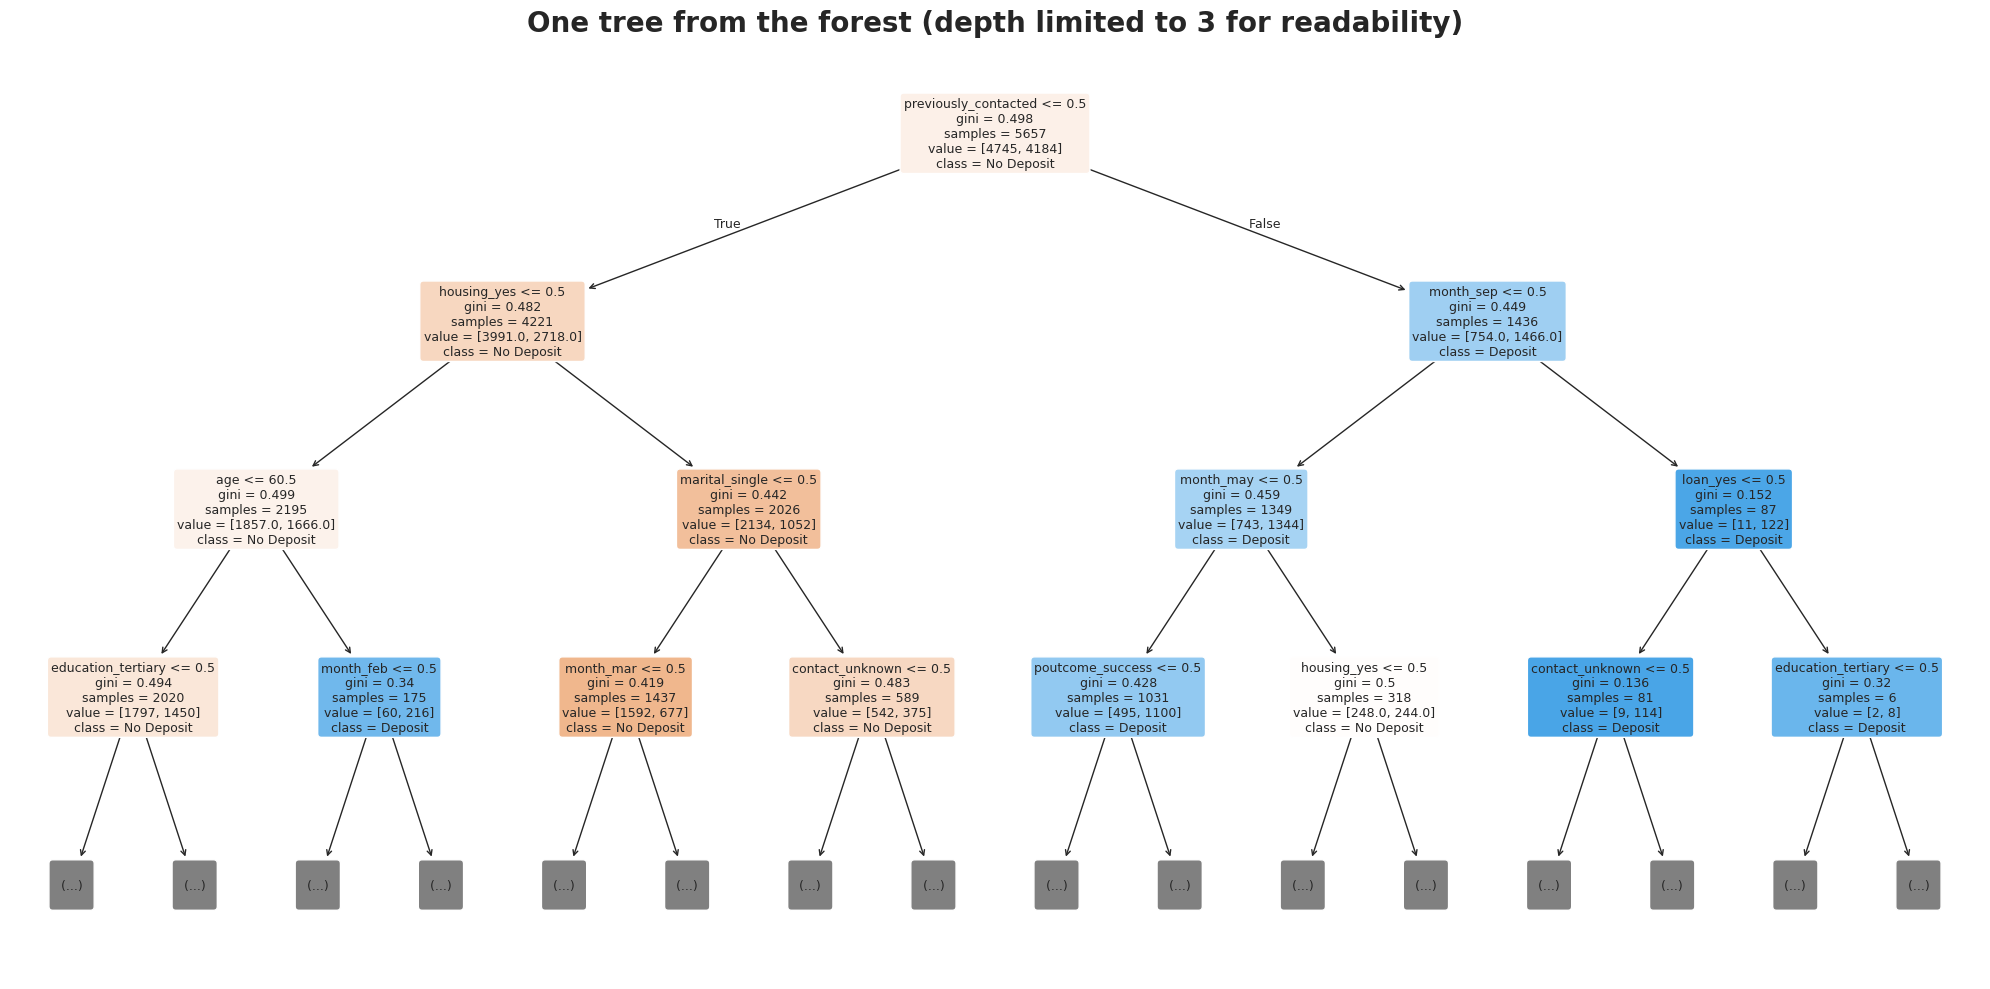

In [11]:

single_tree = rf_model.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(
    single_tree,
    max_depth=3,                       # only show top 3 levels
    feature_names=X.columns,
    class_names=["No Deposit", "Deposit"],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("One tree from the forest (depth limited to 3 for readability)", fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()

## **Business Value**

*  Precision ≈ 78% → ~4 of every 5 clients flagged as "will subscribe" actually do.
*   Recall ≈ 78% → captures ~3 of every 4 potential subscribers.
*   Threshold tuning allows shifting the operating point to match the asymmetric cost of missing a buyer (FN) vs. calling a non-buyer (FP).
*   Top predictors (poutcome, month, contact, balance, campaign) are all known before the call → model is production-ready.